**1. Візуалізація**

<Axes: >

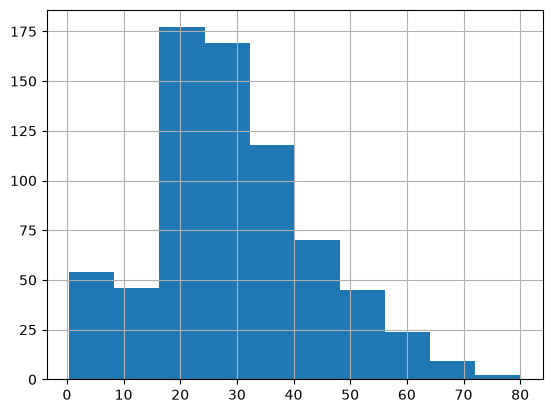

In [17]:
import matplotlib.pyplot as plt
import pandas as pd


def load_data(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.lower()
    return df

df = load_data('Titanic-Dataset.csv')

df['age'].hist()

<Axes: xlabel='pclass'>

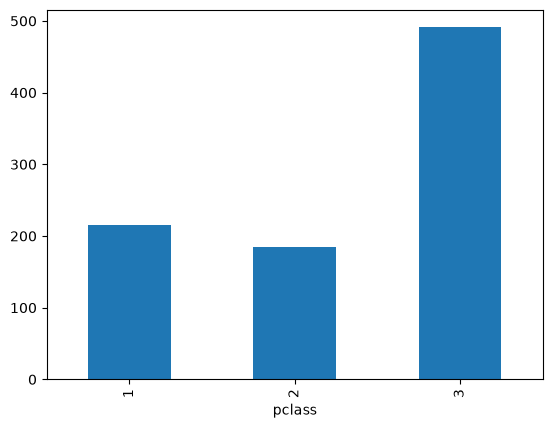

In [24]:
df.pclass.value_counts().sort_index(ascending=True).plot(kind='bar')

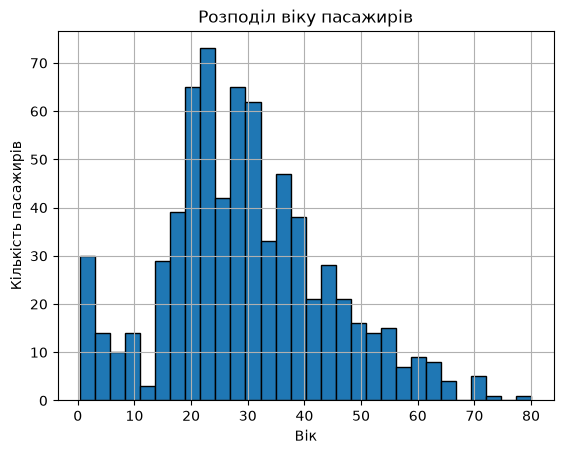

In [26]:
df['age'].hist(bins=30, edgecolor='black')
plt.title('Розподіл віку пасажирів')
plt.xlabel('Вік')
plt.ylabel('Кількість пасажирів')
plt.show();

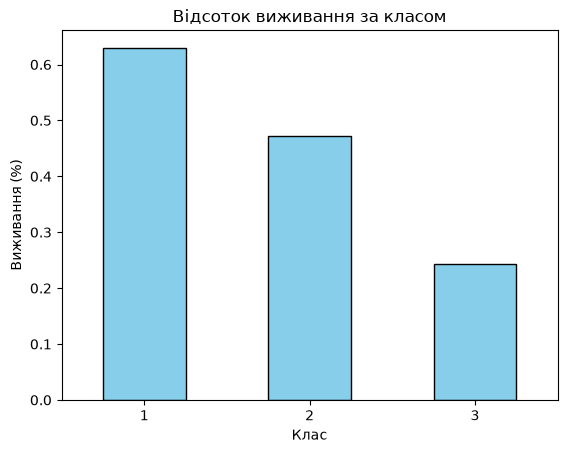

In [57]:
# Діаграма виживання за класом
df.groupby('pclass')['survived'].mean().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Відсоток виживання за класом')
plt.xlabel('Клас')
plt.ylabel('Виживання (%)')
plt.xticks(rotation=0)
plt.show()

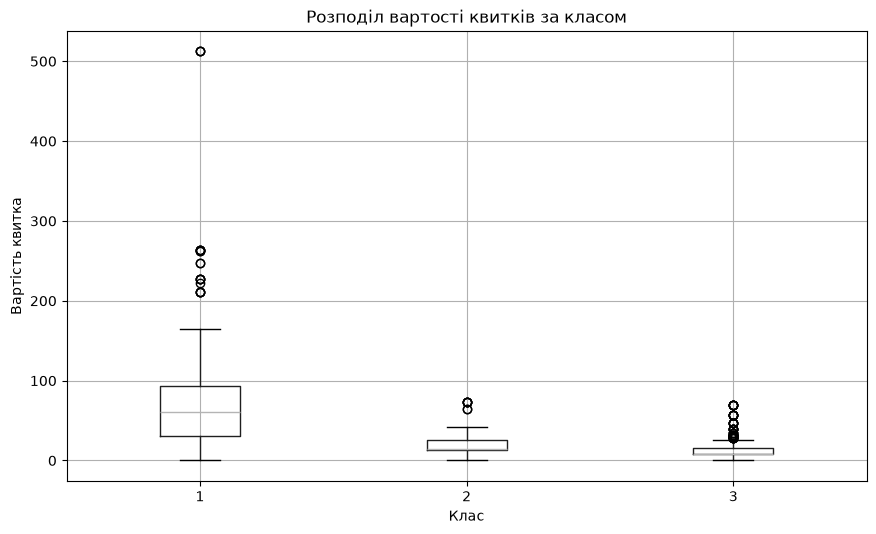

In [29]:
# Boxplot - розподіл вартості квитків за класом
df.boxplot(column='fare', by='pclass', figsize=(10, 6))
plt.title('Розподіл вартості квитків за класом')
plt.suptitle('')  # Видаляємо автоматичний заголовок, який додає pandas
plt.xlabel('Клас')
plt.ylabel('Вартість квитка')
plt.show()

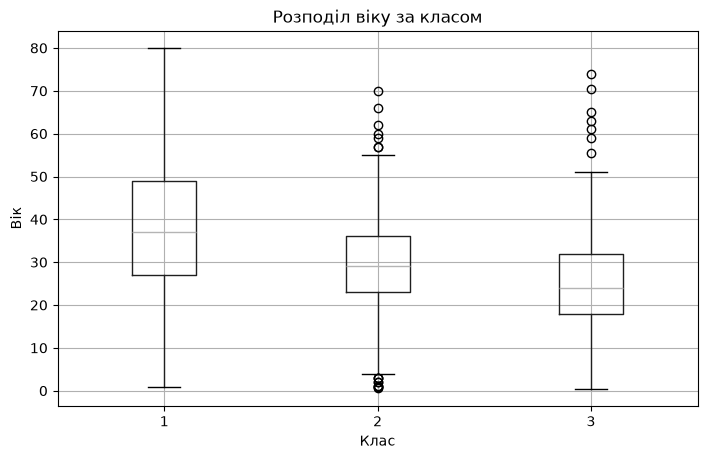

In [31]:
# Boxplot - розподіл віку за класом
df.boxplot(column='age', by='pclass', figsize=(8, 5))
plt.title('Розподіл віку за класом')
plt.suptitle('')  # Видаляємо автоматичний заголовок, який додає pandas
plt.xlabel('Клас')
plt.ylabel('Вік')
plt.show()

In [33]:
df.groupby(['pclass', 'sex'])['age'].mean()

pclass  sex   
1       female    34.611765
        male      41.281386
2       female    28.722973
        male      30.740707
3       female    21.750000
        male      26.507589
Name: age, dtype: float64

In [34]:
df.groupby(['pclass', 'sex'])['age'].mean().unstack()

sex,female,male
pclass,,
1,34.611765,41.281386
2,28.722973,30.740707
3,21.750000,26.507589


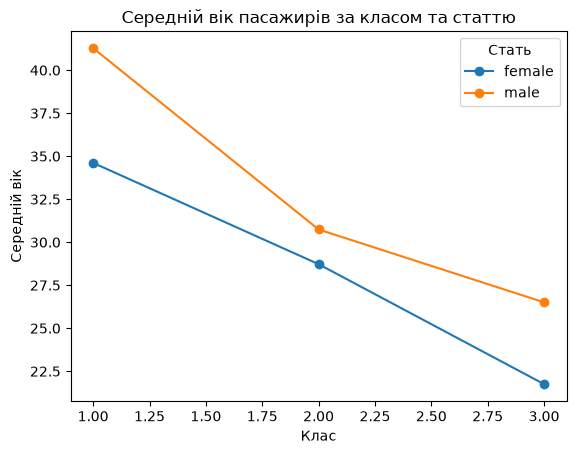

In [32]:
# Лінійний графік - середній вік пасажирів за класом та статтю
df.groupby(['pclass', 'sex'])['age'].mean().unstack().plot(kind='line', marker='o')
plt.title('Середній вік пасажирів за класом та статтю')
plt.xlabel('Клас')
plt.ylabel('Середній вік')
plt.legend(title='Стать')
plt.xticks(rotation=0)
plt.show()

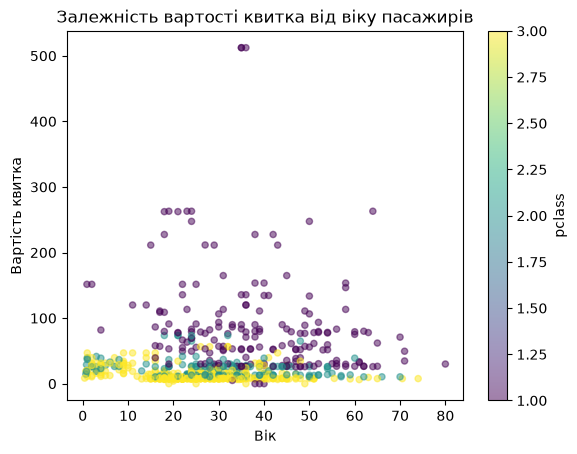

In [35]:
# Scatter plot - вік проти вартості квитка (Графік розсіювання)
df.plot.scatter(x='age', y='fare', alpha=0.5, c='pclass', colormap='viridis') #, figsize=(10, 6))
plt.title('Залежність вартості квитка від віку пасажирів')
plt.xlabel('Вік')
plt.ylabel('Вартість квитка')
plt.show()

In [37]:
import numpy as np

numeric_cols = df.select_dtypes(include=[np.number]).columns
correlation = df[numeric_cols].corr()

In [38]:
correlation

,passengerid,survived,pclass,age,sibsp,parch,fare
passengerid,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
sibsp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


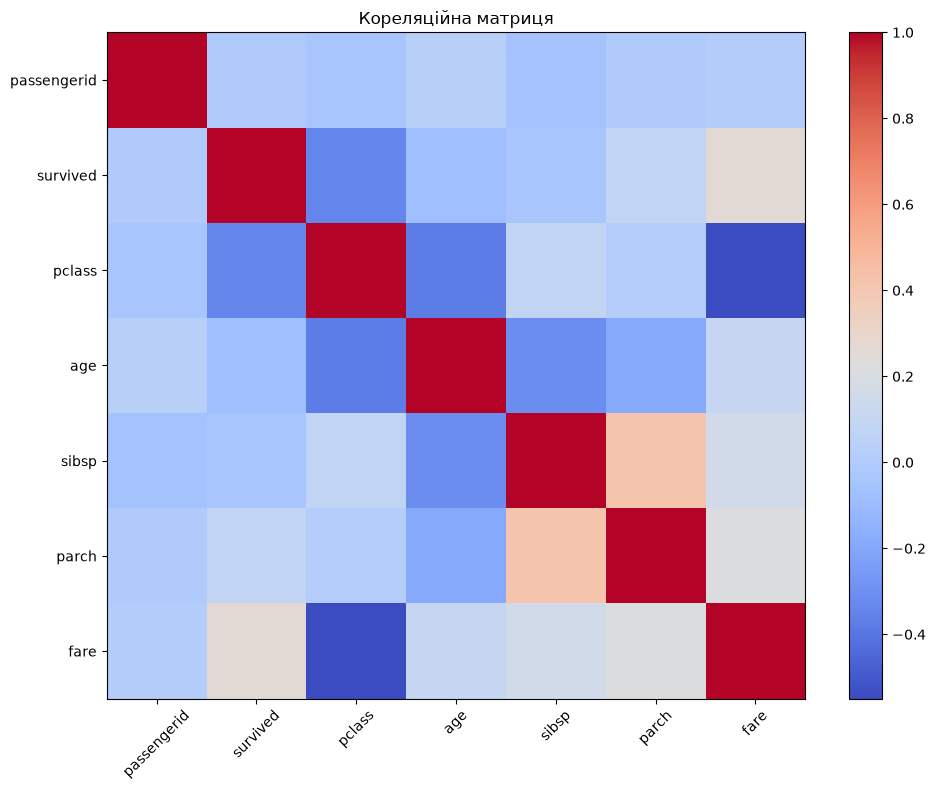

In [40]:
# Кореляційна матриця

import numpy as np

numeric_cols = df.select_dtypes(include=[np.number]).columns
correlation = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(correlation, cmap='coolwarm', aspect='auto')
plt.colorbar()
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title('Кореляційна матриця')
plt.tight_layout()
plt.show()

In [42]:
# Інтерактивні візуалізації з Plotly
import plotly.express as px
import plotly.graph_objects as go

In [43]:
# Інтерактивна гістограма
fig = px.histogram(df, x='age', nbins=30, 
                   title='Розподіл віку пасажирів (інтерактивно)',
                   labels={'age': 'Вік'},
                   color_discrete_sequence=['skyblue'])
fig.show()

In [49]:
# Інтерактивний scatter plot
fig = px.scatter(df, x='age', y='fare', color='survived',
                 size='pclass', 
                 hover_data=['name', 'pclass'],
                 title='Залежність вартості квитка від віку пасажирів (інтерактивно)',
                 labels={'age': 'Вік', 'fare': 'Вартість квитка', 'pclass': 'Клас'},
                 color_continuous_scale='RdYlGn')
fig.show()

In [50]:
# Boxplot з Plotly
fig = px.box(df, x='pclass', y='age', color='sex',
             title='Розподіл віку пасажирів за класом і статтю (інтерактивно)',
             labels={'pclass': 'Клас', 'age': 'Вік'},
             color_discrete_sequence=['pink', 'lightblue'])
fig.show()

In [51]:
# Sunburst - ієрархічна візуалізація
df_hierarchy = df.groupby(['pclass', 'sex', 'survived']).size().reset_index(name='count')
fig = px.sunburst(df_hierarchy, 
                  path=['pclass', 'sex', 'survived'], 
                  values='count', 
                  title='Ієрархія виживання: Клас -> Стать -> Виживання')
fig.show()

In [54]:
# Heatmap - тепловий графік кореляційної матриці
numeric = df.select_dtypes(include=[np.number])
correlation = numeric.corr()

fig = px.imshow(correlation, 
                text_auto='.2f', 
                aspect="auto",
                title='Кореляційна матриця',
                color_continuous_scale='RdBu_r',
                zmin=-1, zmax=1)
fig.show()


In [55]:
# 3D Scatter Plot - тривимірний графік розсіювання
fig = px.scatter_3d(df.dropna(subset=['age']),
                     x='age', y='fare', z='pclass',
                     color='survived',
                     hover_data=['name'],
                     title='3D Scatter Plot: Вік, Вартість квитка та Клас (інтерактивно)',
                     labels={'survived': 'Вижив'})
fig.show()